# Handwritten Digit Clustering with K-Means


## Project objective
Explore whether K-Means can group handwritten digit images by similarity without using their labels during training. Compare initialization strategies, evaluate cluster quality, visualize clusters, and study the effect of the number of clusters.


## 1. Imports and reproducibility

We use a fixed random seed where appropriate so results are easier to reproduce. The notebook uses Scikit-learn's built-in dataset, so no external data download is required.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn import metrics

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Imports completed.")

Imports completed.


## 2. Load and inspect the data

Each image is an 8×8 grayscale image flattened into 64 numeric features. The labels tell us the actual digit (0–9), but are reserved for evaluation after clustering.

Number of images: 1797
Number of pixel features per image: 64
Number of known digit classes: 10
Pixel value range: 0.0 to 16.0


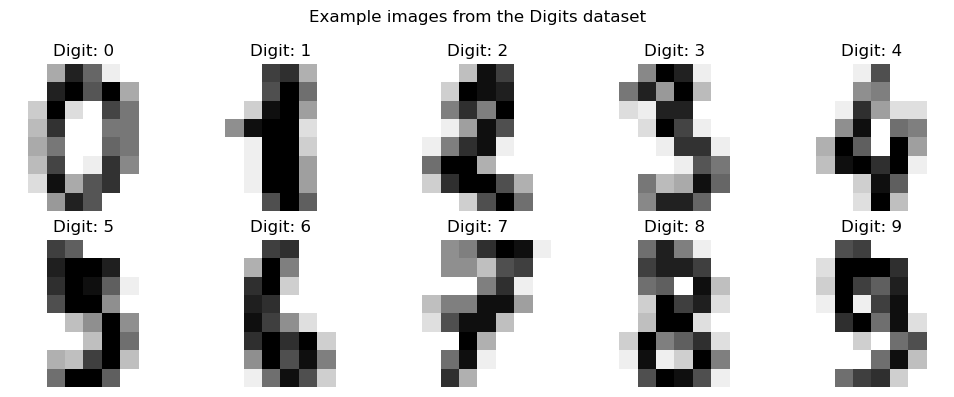

In [2]:
digits = load_digits()
X = digits.data
y_true = digits.target
images = digits.images

print(f"Number of images: {X.shape[0]}")
print(f"Number of pixel features per image: {X.shape[1]}")
print(f"Number of known digit classes: {np.unique(y_true).size}")
print(f"Pixel value range: {X.min()} to {X.max()}")

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    idx = np.where(y_true == digit)[0][0]
    ax.imshow(images[idx], cmap="gray_r")
    ax.set_title(f"Digit: {digit}")
    ax.axis("off")
plt.suptitle("Example images from the Digits dataset")
plt.tight_layout()
plt.show()

## 3. Scale the features

K-Means uses Euclidean distance, so feature scaling can affect the resulting clusters. We standardize each pixel feature and then use this same scaled representation consistently for fitting and evaluation.

This is an unsupervised exploration of one complete built-in dataset, not a supervised train/test prediction task.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print("Mean of first three scaled features:", np.round(X_scaled.mean(axis=0)[:3], 3))

Scaled data shape: (1797, 64)
Mean of first three scaled features: [ 0. -0. -0.]


## 4. Evaluation metrics

We report:
- **Inertia:** within-cluster sum of squared distances; lower is better for a fixed number of clusters, but it generally decreases as the cluster count increases.
- **ARI and AMI:** agreement with the known digit labels, adjusted for chance.
- **Homogeneity and completeness:** whether clusters mostly contain one digit and whether examples of the same digit are grouped together.
- **Silhouette score:** cohesion and separation, calculated on a reproducible sample to keep execution time reasonable.

ARI/AMI and label-based metrics are diagnostic only. In a real unlabeled problem, ground-truth labels would not be available.

In [4]:
def evaluate_clustering(X_eval, labels_pred, labels_true, inertia, fit_seconds):
    # Use a fixed sample for a repeatable and reasonably fast silhouette estimate.
    silhouette = metrics.silhouette_score(
        X_eval,
        labels_pred,
        metric="euclidean",
        sample_size=min(500, len(X_eval)),
        random_state=RANDOM_STATE,
    )
    return {
        "fit_time_sec": fit_seconds,
        "inertia": inertia,
        "homogeneity": metrics.homogeneity_score(labels_true, labels_pred),
        "completeness": metrics.completeness_score(labels_true, labels_pred),
        "v_measure": metrics.v_measure_score(labels_true, labels_pred),
        "ARI": metrics.adjusted_rand_score(labels_true, labels_pred),
        "AMI": metrics.adjusted_mutual_info_score(labels_true, labels_pred),
        "silhouette": silhouette,
    }

print("Evaluation function ready.")

Evaluation function ready.


## 5. Compare initialization strategies

We compare `k-means++`, `random`, and a PCA-based initialization. K-Means++ and random initialization are repeated with several seeds to show run-to-run variation. PCA is fitted on the same scaled feature space; its principal-component vectors are used as deterministic initial centers, matching the educational comparison approach.

**Interpretation note:** PCA components are directions in feature space, not observed images. PCA-based initialization is included as an experiment, not assumed to be the best method.

In [5]:
N_CLUSTERS = 10
N_REPEATS = 5
results = []

# Repeated stochastic initializations
for init_method in ["k-means++", "random"]:
    for seed in range(N_REPEATS):
        model = KMeans(
            n_clusters=N_CLUSTERS,
            init=init_method,
            n_init=1,
            random_state=seed,
            max_iter=300,
        )
        start = time.perf_counter()
        model.fit(X_scaled)
        elapsed = time.perf_counter() - start

        row = evaluate_clustering(
            X_scaled, model.labels_, y_true, model.inertia_, elapsed
        )
        row.update({"initialization": init_method, "run": seed + 1})
        results.append(row)

# Deterministic PCA-based initialization in the same scaled feature space
pca_init = PCA(n_components=N_CLUSTERS, random_state=RANDOM_STATE).fit(X_scaled)
pca_model = KMeans(
    n_clusters=N_CLUSTERS,
    init=pca_init.components_,
    n_init=1,
    random_state=RANDOM_STATE,
    max_iter=300,
)
start = time.perf_counter()
pca_model.fit(X_scaled)
elapsed = time.perf_counter() - start
row = evaluate_clustering(
    X_scaled, pca_model.labels_, y_true, pca_model.inertia_, elapsed
)
row.update({"initialization": "PCA-based", "run": 1})
results.append(row)

results_df = pd.DataFrame(results)
display(results_df.round(4))

,fit_time_sec,inertia,homogeneity,completeness,v_measure,ARI,AMI,silhouette,initialization,run
0,0.3819,69749.0825,0.6722,0.7199,0.6952,0.5593,0.6920,0.1529,k-means++,1
1,0.0929,70785.0304,0.6653,0.6924,0.6785,0.5554,0.6753,0.1492,k-means++,2
2,0.0809,69416.8400,0.6041,0.6527,0.6275,0.4675,0.6235,0.1464,k-means++,3
3,0.0864,71714.5312,0.6587,0.6853,0.6717,0.5378,0.6684,0.1316,k-means++,4
4,0.0793,71687.1250,0.6997,0.7109,0.7053,0.6079,0.7023,0.1292,k-means++,5
5,0.0859,70680.1754,0.5577,0.6235,0.5887,0.4321,0.5842,0.1380,random,1
6,0.0764,69480.7543,0.6047,0.6520,0.6275,0.4754,0.6235,0.1413,random,2
7,0.0786,71303.3692,0.5461,0.6160,0.5790,0.4152,0.5744,0.1288,random,3
8,0.0859,71923.6545,0.6855,0.7039,0.6946,0.5885,0.6915,0.1335,random,4
9,0.0768,71374.4548,0.6351,0.6902,0.6615,0.5201,0.6579,0.1410,random,5


## 6. Summarize stability and average performance

For stochastic strategies, the mean and standard deviation across runs show how much the results vary with initialization. The PCA-based strategy has one deterministic run here, so it has no meaningful across-run standard deviation.

,initialization,runs,fit_time_mean,fit_time_std,inertia_mean,inertia_std,ARI_mean,ARI_std,AMI_mean,silhouette_mean,silhouette_std
0,PCA-based,1,0.0899,NaN,70791.2676,NaN,0.5538,NaN,0.6768,0.1470,NaN
1,k-means++,5,0.1443,0.1329,70670.5218,1067.3938,0.5456,0.0508,0.6723,0.1419,0.0107
2,random,5,0.0807,0.0048,70952.4817,933.3397,0.4863,0.0701,0.6263,0.1365,0.0053


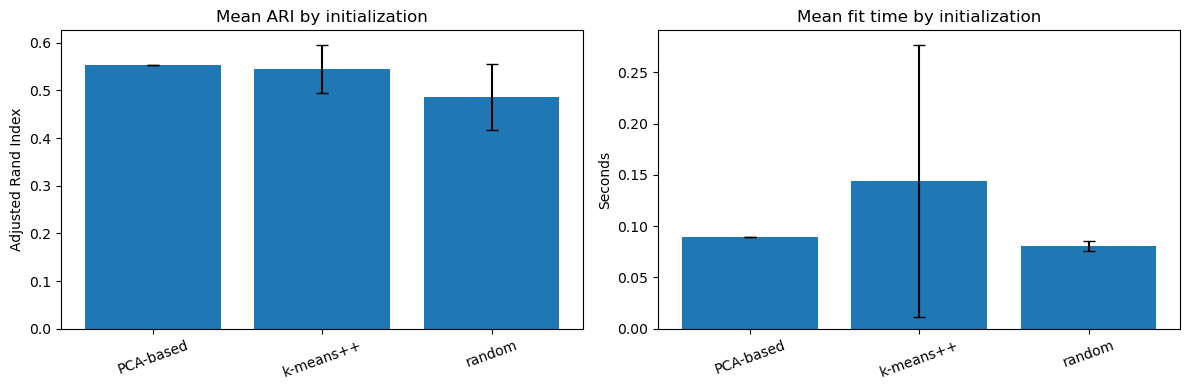

In [6]:
summary_df = (
    results_df.groupby("initialization")
    .agg(
        runs=("run", "count"),
        fit_time_mean=("fit_time_sec", "mean"),
        fit_time_std=("fit_time_sec", "std"),
        inertia_mean=("inertia", "mean"),
        inertia_std=("inertia", "std"),
        ARI_mean=("ARI", "mean"),
        ARI_std=("ARI", "std"),
        AMI_mean=("AMI", "mean"),
        silhouette_mean=("silhouette", "mean"),
        silhouette_std=("silhouette", "std"),
    )
    .reset_index()
)
display(summary_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(summary_df["initialization"], summary_df["ARI_mean"],
            yerr=summary_df["ARI_std"].fillna(0), capsize=4)
axes[0].set_title("Mean ARI by initialization")
axes[0].set_ylabel("Adjusted Rand Index")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(summary_df["initialization"], summary_df["fit_time_mean"],
            yerr=summary_df["fit_time_std"].fillna(0), capsize=4)
axes[1].set_title("Mean fit time by initialization")
axes[1].set_ylabel("Seconds")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 7. Select a representative K-Means++ run and visualize clusters

We fit one reproducible K-Means++ model. PCA is used only to project the scaled data and centroids into two dimensions for visualization; the clustering itself is still performed in the original 64-feature space.

The 2D plot is therefore a projection of the 64-dimensional clusters, not a new clustering performed in two dimensions.

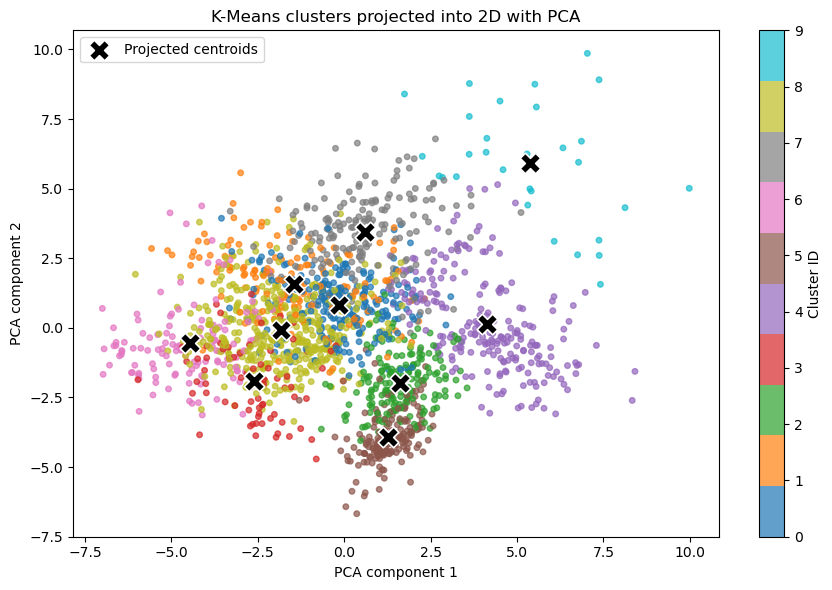

Explained variance by first two PCA components: 21.6%


In [7]:
representative_model = KMeans(
    n_clusters=N_CLUSTERS,
    init="k-means++",
    n_init=10,
    random_state=RANDOM_STATE,
    max_iter=300,
)
representative_model.fit(X_scaled)
cluster_ids = representative_model.labels_

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_2d.fit_transform(X_scaled)
centers_2d = pca_2d.transform(representative_model.cluster_centers_)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=cluster_ids, cmap="tab10", s=16, alpha=0.7
)
plt.scatter(
    centers_2d[:, 0], centers_2d[:, 1],
    marker="X", s=220, c="black", edgecolor="white", linewidth=1.2,
    label="Projected centroids"
)
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("K-Means clusters projected into 2D with PCA")
plt.legend()
plt.colorbar(scatter, label="Cluster ID")
plt.tight_layout()
plt.show()

print("Explained variance by first two PCA components:",
      f"{pca_2d.explained_variance_ratio_.sum():.1%}")

## 8. Inspect the true digit composition of each cluster

Cluster IDs are arbitrary and do not necessarily correspond to digit labels. This heatmap shows how many examples of each true digit fall into each cluster, helping identify mixed clusters and patterns that K-Means captures.

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0,107,21,7,1,1,5,0,101,2
1,0,1,0,3,2,137,0,1,7,5
2,176,0,0,0,0,0,1,0,0,0
3,0,27,43,1,0,0,0,0,0,0
4,2,46,3,0,159,2,0,2,3,15
5,0,0,0,0,0,2,175,0,2,0
6,0,0,104,9,0,0,0,7,7,0
7,0,0,1,7,10,0,0,152,4,9
8,0,1,5,156,0,40,0,0,50,145


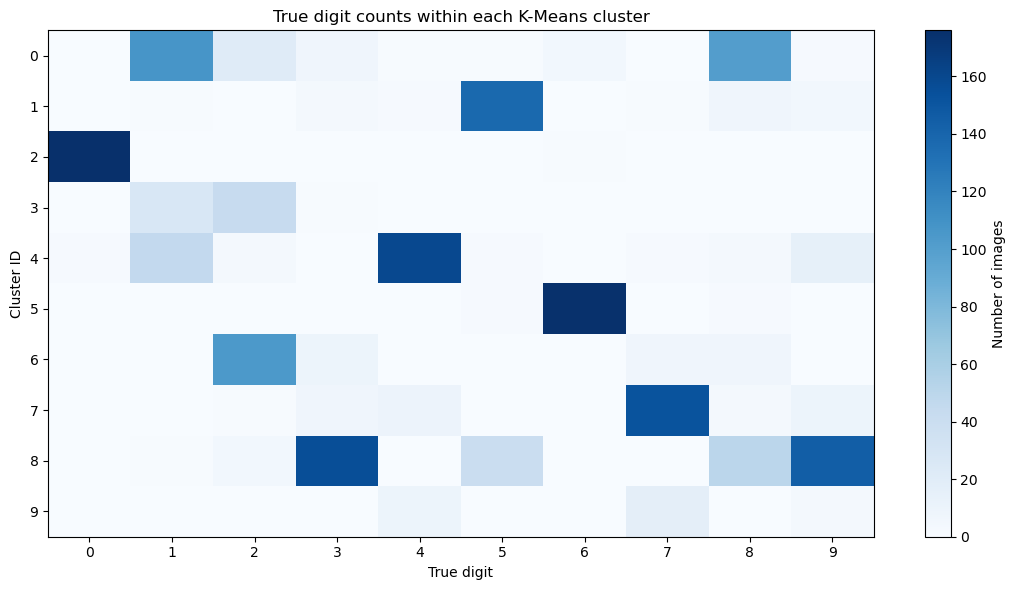

In [8]:
composition = pd.crosstab(
    pd.Series(cluster_ids, name="Cluster"),
    pd.Series(y_true, name="True digit"),
)
display(composition)

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(composition.values, aspect="auto", cmap="Blues")
ax.set_xticks(np.arange(len(composition.columns)))
ax.set_xticklabels(composition.columns)
ax.set_yticks(np.arange(len(composition.index)))
ax.set_yticklabels(composition.index)
ax.set_xlabel("True digit")
ax.set_ylabel("Cluster ID")
ax.set_title("True digit counts within each K-Means cluster")
fig.colorbar(im, ax=ax, label="Number of images")
plt.tight_layout()
plt.show()

## 9. View sample images from each cluster

This section displays a few original images from each cluster. It helps connect the numeric evaluation to the actual handwritten digits and makes mixed clusters easier to investigate.

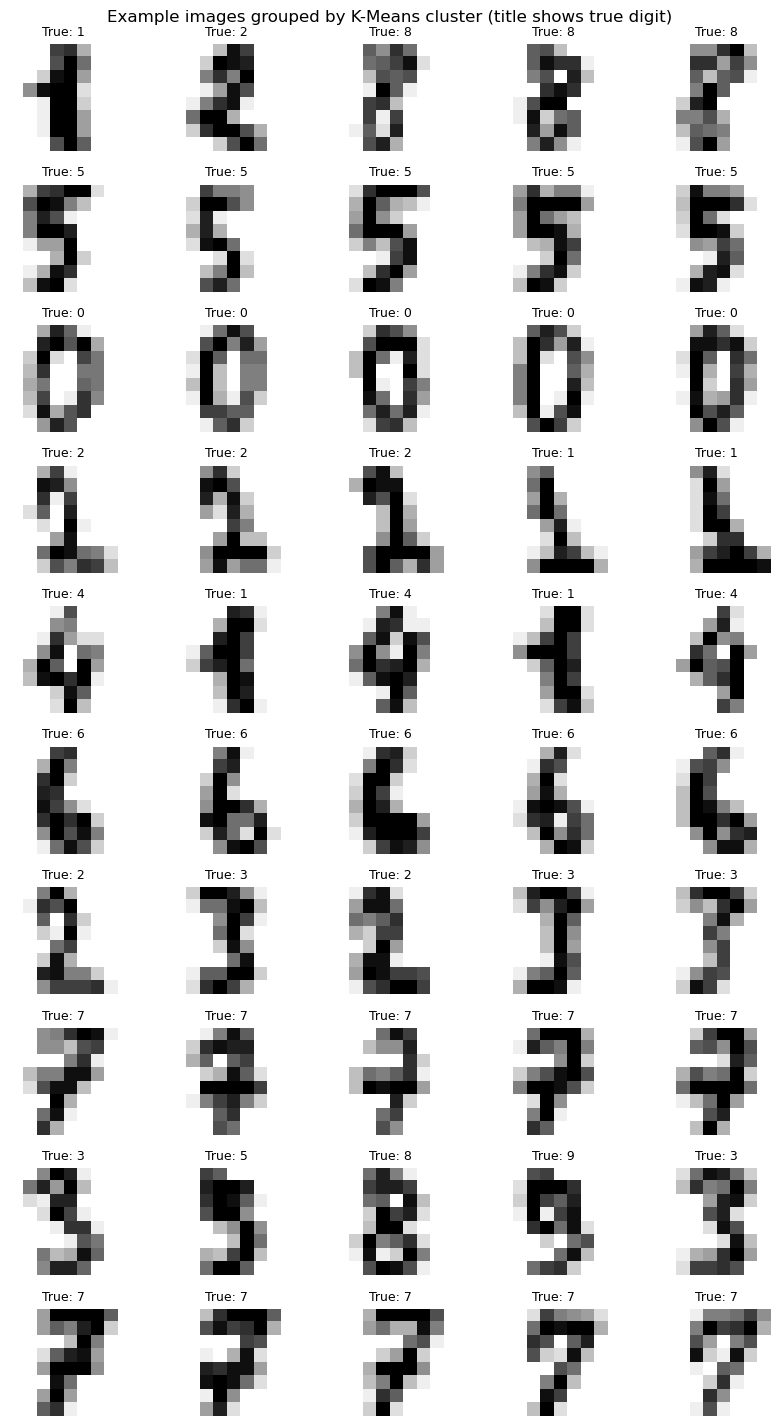

In [9]:
N_IMAGES_PER_CLUSTER = 5
fig, axes = plt.subplots(
    N_CLUSTERS, N_IMAGES_PER_CLUSTER,
    figsize=(N_IMAGES_PER_CLUSTER * 1.7, N_CLUSTERS * 1.45)
)

for cluster_id in range(N_CLUSTERS):
    members = np.where(cluster_ids == cluster_id)[0]
    # Deterministic sample selection for reproducibility
    selected = members[:N_IMAGES_PER_CLUSTER]
    for col in range(N_IMAGES_PER_CLUSTER):
        ax = axes[cluster_id, col]
        ax.axis("off")
        if col < len(selected):
            idx = selected[col]
            ax.imshow(images[idx], cmap="gray_r")
            ax.set_title(f"True: {y_true[idx]}", fontsize=9)
    axes[cluster_id, 0].set_ylabel(f"Cluster {cluster_id}", fontsize=9)

plt.suptitle("Example images grouped by K-Means cluster (title shows true digit)")
plt.tight_layout()
plt.show()

## 10. Study the effect of the number of clusters

We compare several values of `k` using inertia and silhouette score. Inertia always tends to decrease as `k` increases, so it should be interpreted alongside silhouette and the project's practical objective rather than used alone.

,k,inertia,silhouette,fit_time_sec
0,2,100435.5444,0.1021,0.3675
1,3,93842.4827,0.1025,0.3839
2,4,89554.6360,0.0883,0.3934
3,5,85096.0547,0.1043,0.4342
4,6,81736.9459,0.1017,0.4162
5,7,78071.3389,0.1105,0.4010
6,8,75089.6875,0.1263,0.4805
7,9,73002.3132,0.1407,0.4796
8,10,69845.7847,0.1419,0.4632
9,11,67283.4237,0.1498,0.4632


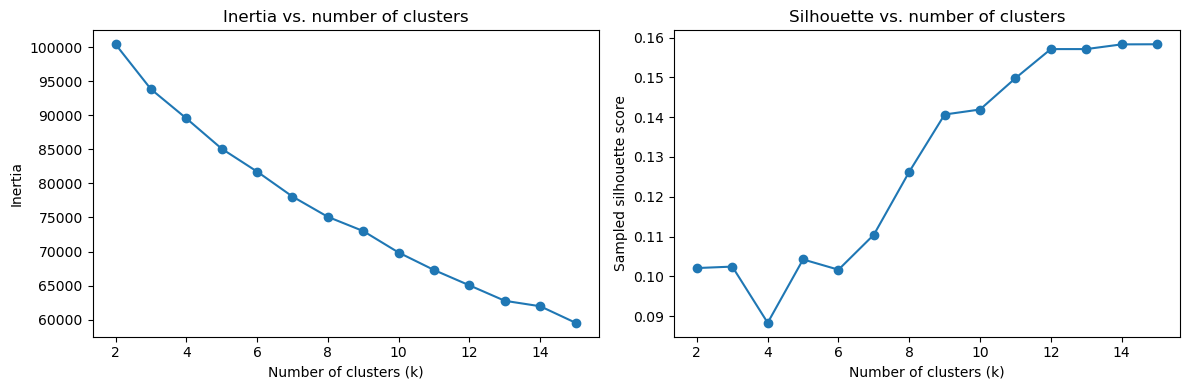

In [10]:
k_values = range(2, 16)
k_results = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        random_state=RANDOM_STATE,
        max_iter=300,
    )
    start = time.perf_counter()
    model.fit(X_scaled)
    elapsed = time.perf_counter() - start

    sil = metrics.silhouette_score(
        X_scaled, model.labels_,
        metric="euclidean",
        sample_size=min(500, len(X_scaled)),
        random_state=RANDOM_STATE,
    )
    k_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": sil,
        "fit_time_sec": elapsed,
    })

k_results_df = pd.DataFrame(k_results)
display(k_results_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_results_df["k"], k_results_df["inertia"], marker="o")
axes[0].set_title("Inertia vs. number of clusters")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_results_df["k"], k_results_df["silhouette"], marker="o")
axes[1].set_title("Silhouette vs. number of clusters")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Sampled silhouette score")
plt.tight_layout()
plt.show()